# This is the python file that filters through and cleans Wifi dataset.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("Wifi.csv")
df.head()

,date,hour,building_floor,building_desc,latitude,longitude,building_type,density_cnt,capacity,dc_ratio
0,2021-03-31,1,4,209 BAY STATE ROAD,42.3507,-71.1028,Residential,1,8,0.13
1,2021-03-31,1,2,200-202 BAY STATE ROAD,42.3503,-71.1026,Residential,1,12,0.08
2,2021-03-31,1,2,184 BAY STATE ROAD,42.3503,-71.1019,Residential,1,6,0.17
3,2021-03-31,1,3,190 BAY STATE ROAD,42.3503,-71.1021,Residential,1,9,0.11
4,2021-03-31,1,3,161 BAY STATE ROAD,42.3506,-71.1009,Residential,1,5,0.20


First, we will take a look at the columns/variables.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12314168 entries, 0 to 12314167
Data columns (total 10 columns):
 #   Column          Dtype  
---  ------          -----  
 0   date            object 
 1   hour            int64  
 2   building_floor  object 
 3   building_desc   object 
 4   latitude        float64
 5   longitude       float64
 6   building_type   object 
 7   density_cnt     int64  
 8   capacity        int64  
 9   dc_ratio        float64
dtypes: float64(3), int64(3), object(4)
memory usage: 939.5+ MB


Initial Questions To Consider:

This dataset contains 10 columns (variables).

This dataset has 12314168 rows (observations), indicating there are 12314168 Wifi information.

There are both categorical and numerical variables. At quick glance there seems to be same number of numerical variables as categorical variables.

Categorical Variables: building_type, building_floor, hour

Numerical Variables: density_cnt, capacity, dc_ratio


### Data Completion

Information on how much data is provided

In [ ]:
df.isnull().sum()

date                   0
hour                   0
building_floor         0
building_desc          0
latitude          143748
longitude         143748
building_type          0
density_cnt            0
capacity               0
dc_ratio               0
dtype: int64

Some of the data is missing from the dataset.

Columns with missing data points: latitude, longitude

However, even if some of the data point is missing, those two columns are only marking the geographical locations, which are insignificant. In fact, in the data cleaning process, we will drop those columns.

### Data Cleaning

As mentioned, we will delete latitude and longitude columns.

In [ ]:
df.drop(['latitude', 'longitude'],axis=1, inplace=True)
df.head()

,date,hour,building_floor,building_desc,building_type,density_cnt,capacity,dc_ratio
0,2021-03-31,1,4,209 BAY STATE ROAD,Residential,1,8,0.13
1,2021-03-31,1,2,200-202 BAY STATE ROAD,Residential,1,12,0.08
2,2021-03-31,1,2,184 BAY STATE ROAD,Residential,1,6,0.17
3,2021-03-31,1,3,190 BAY STATE ROAD,Residential,1,9,0.11
4,2021-03-31,1,3,161 BAY STATE ROAD,Residential,1,5,0.20


Now that we have cleaned the data set, we will look more about each columns.

In [ ]:
df.describe()

,hour,density_cnt,capacity,dc_ratio
count,1.231417e+07,1.231417e+07,1.231417e+07,1.231417e+07
mean,1.371463e+01,1.110039e+01,5.507822e+01,2.522285e-01
std,6.217759e+00,2.317740e+01,8.962519e+01,4.153055e-01
min,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00
25%,9.000000e+00,2.000000e+00,4.000000e+00,2.000000e-02
50%,1.400000e+01,4.000000e+00,1.600000e+01,1.300000e-01
75%,1.900000e+01,1.100000e+01,6.800000e+01,3.300000e-01
max,2.300000e+01,1.857000e+03,2.660000e+03,6.403000e+01


Since the data reports the building_desc, we will divide the group based on the Building_desc and hour. Just because there is more data from one location does not mean that it is the most popular building, so we will conduct groupby and calculate average of density_cnt, capacity, and dc_ratio.

We will first look at the number of data points per building address and hour.

In [ ]:
df_groupByBuilding = df.groupby(['building_desc', 'hour']).size().reset_index(name='count')
df_groupByBuilding

,building_desc,hour,count
0,1 BUSWELL STREET,0,251
1,1 BUSWELL STREET,1,688
2,1 BUSWELL STREET,2,929
3,1 BUSWELL STREET,3,1039
4,1 BUSWELL STREET,4,1110
...,...,...,...
5821,985 COMMONWEALTH AVENUE,19,1975
5822,985 COMMONWEALTH AVENUE,20,1963
5823,985 COMMONWEALTH AVENUE,21,1946
5824,985 COMMONWEALTH AVENUE,22,1955


We will now plot a bar graph on the average of capacity, density_cnt, and dc_rato based on the building and hour.

However, there are very many buildings listed on the data, so we will plot it per building.

Before plotting them, we will take a look at the mean capacity, dc_ratio, and density_cnt after grouping by building_desc.


In [ ]:
grouped_df = df.groupby('building_desc')[['capacity', 'dc_ratio', 'density_cnt']].mean()
grouped_df

,capacity,dc_ratio,density_cnt
building_desc,,,
1 BUSWELL STREET,3.755505,0.661792,2.851811
1 UNIVERSITY ROAD,162.754299,0.116412,32.116784
10 BUICK STREET,54.114409,0.275676,15.748614
10 COTTAGE FARM ROAD,0.000000,0.000000,2.288339
10 LENOX STREET,32.831234,0.180870,5.820122
...,...,...,...
96 MOUNTFORT STREET,5.917941,0.517392,3.134094
96-100 CUMMINGTON MALL,44.118191,0.112323,10.943112
975 COMMONWEALTH AVENUE,52.679977,0.185252,9.771536


Here is the graph now.

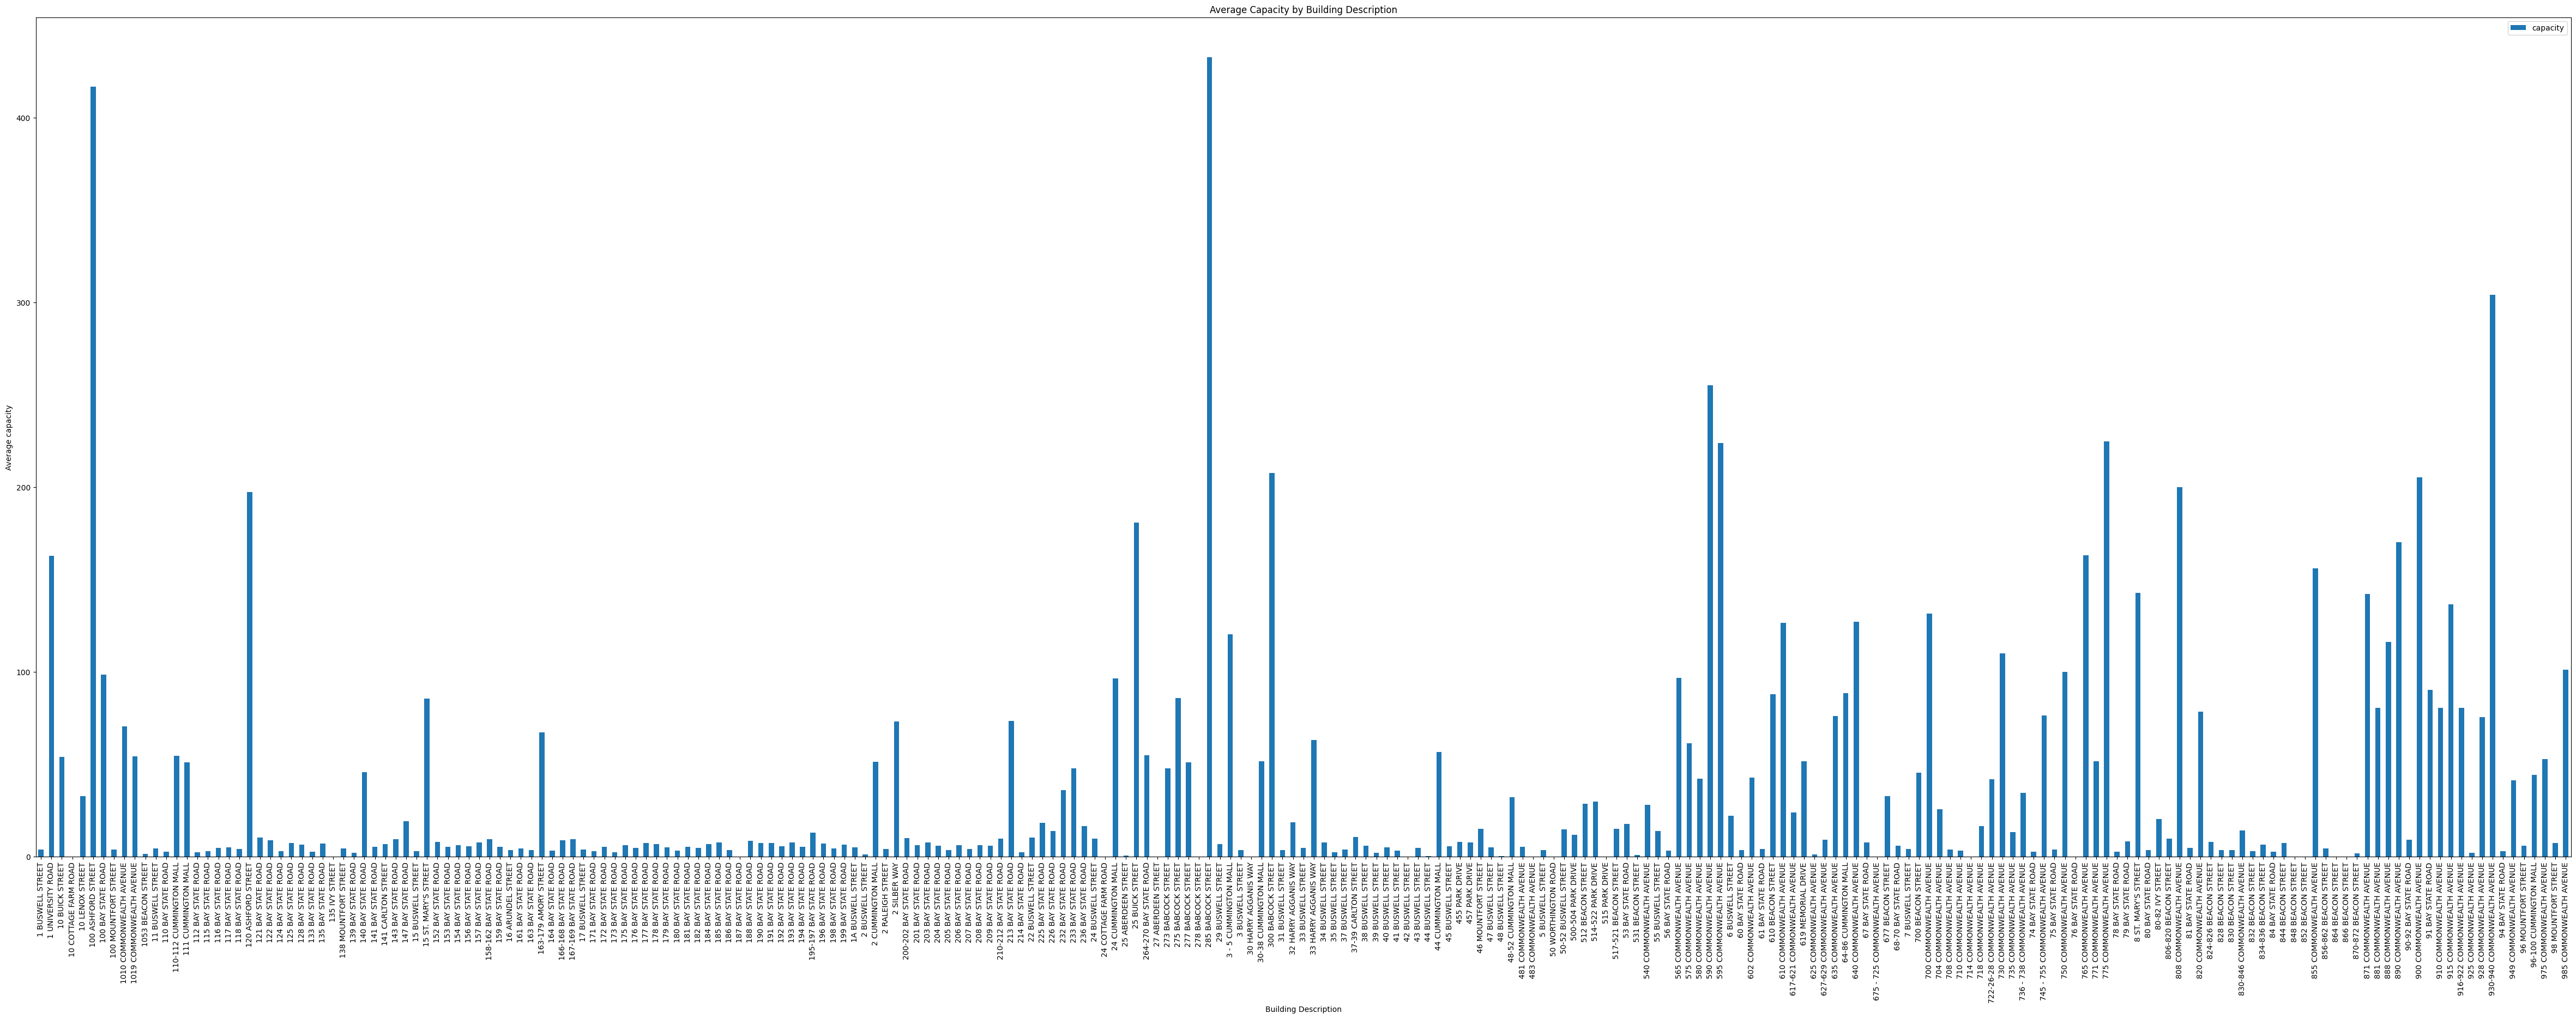

In [ ]:
grouped_df = df.groupby('building_desc')[['capacity']].mean()

grouped_df.plot(kind='bar', figsize=(60, 20))
plt.title('Average Capacity by Building Description')
plt.xlabel('Building Description')
plt.ylabel('Average capacity')
plt.xticks(rotation=90)
plt.show()

From this graph, 285 Babcock Street has the highest average capacity.

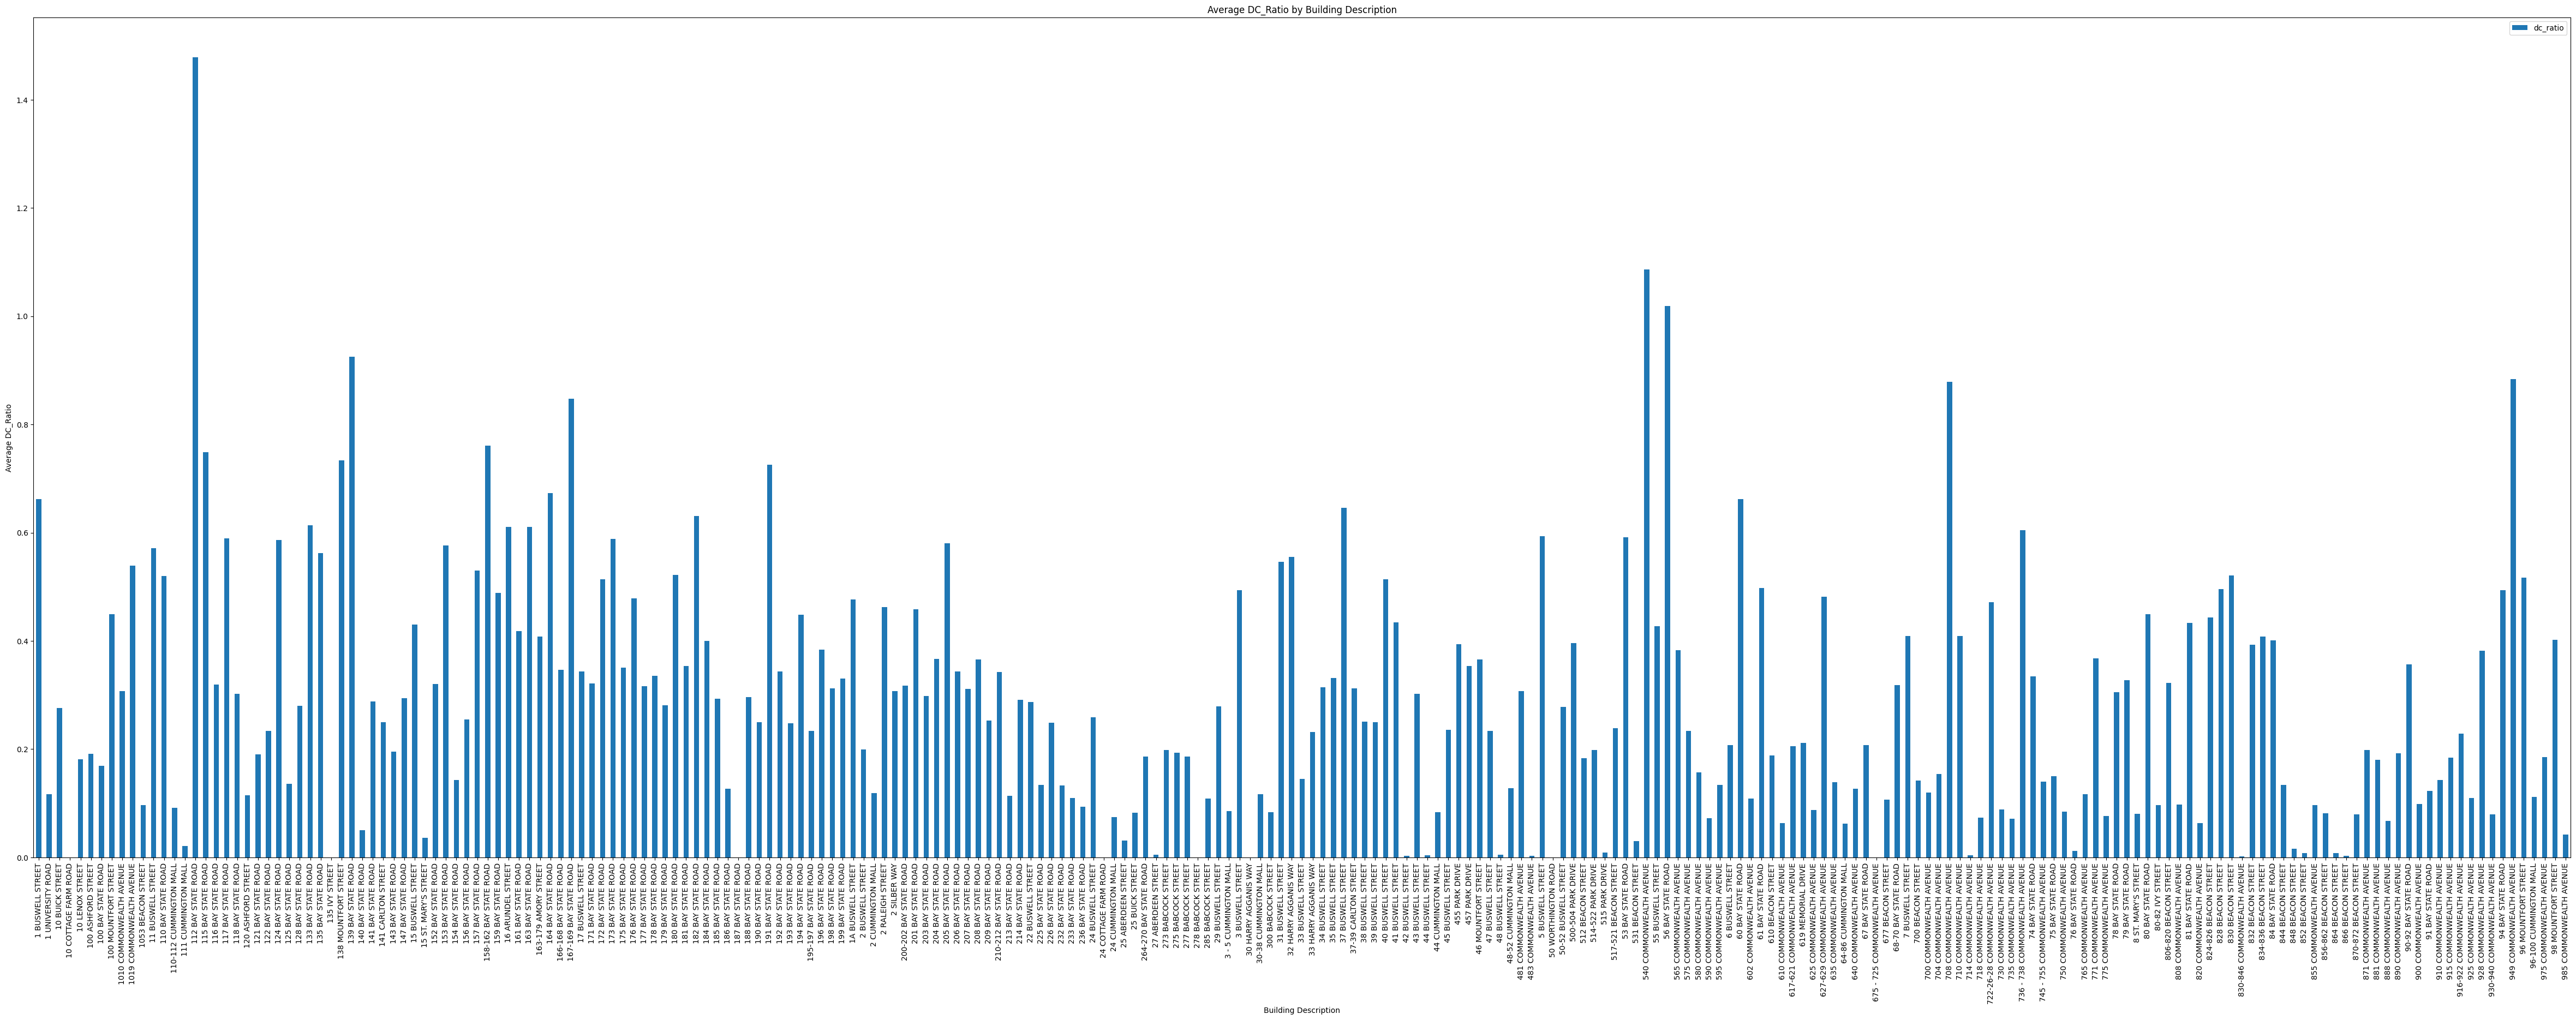

In [ ]:
grouped_df = df.groupby('building_desc')[['dc_ratio']].mean()

grouped_df.plot(kind='bar', figsize=(60, 20))
plt.title('Average DC_Ratio by Building Description')
plt.xlabel('Building Description')
plt.ylabel('Average DC_Ratio')
plt.xticks(rotation=90)
plt.show()

From this graph, 112 Bay State Road has the highest dc_ratio.

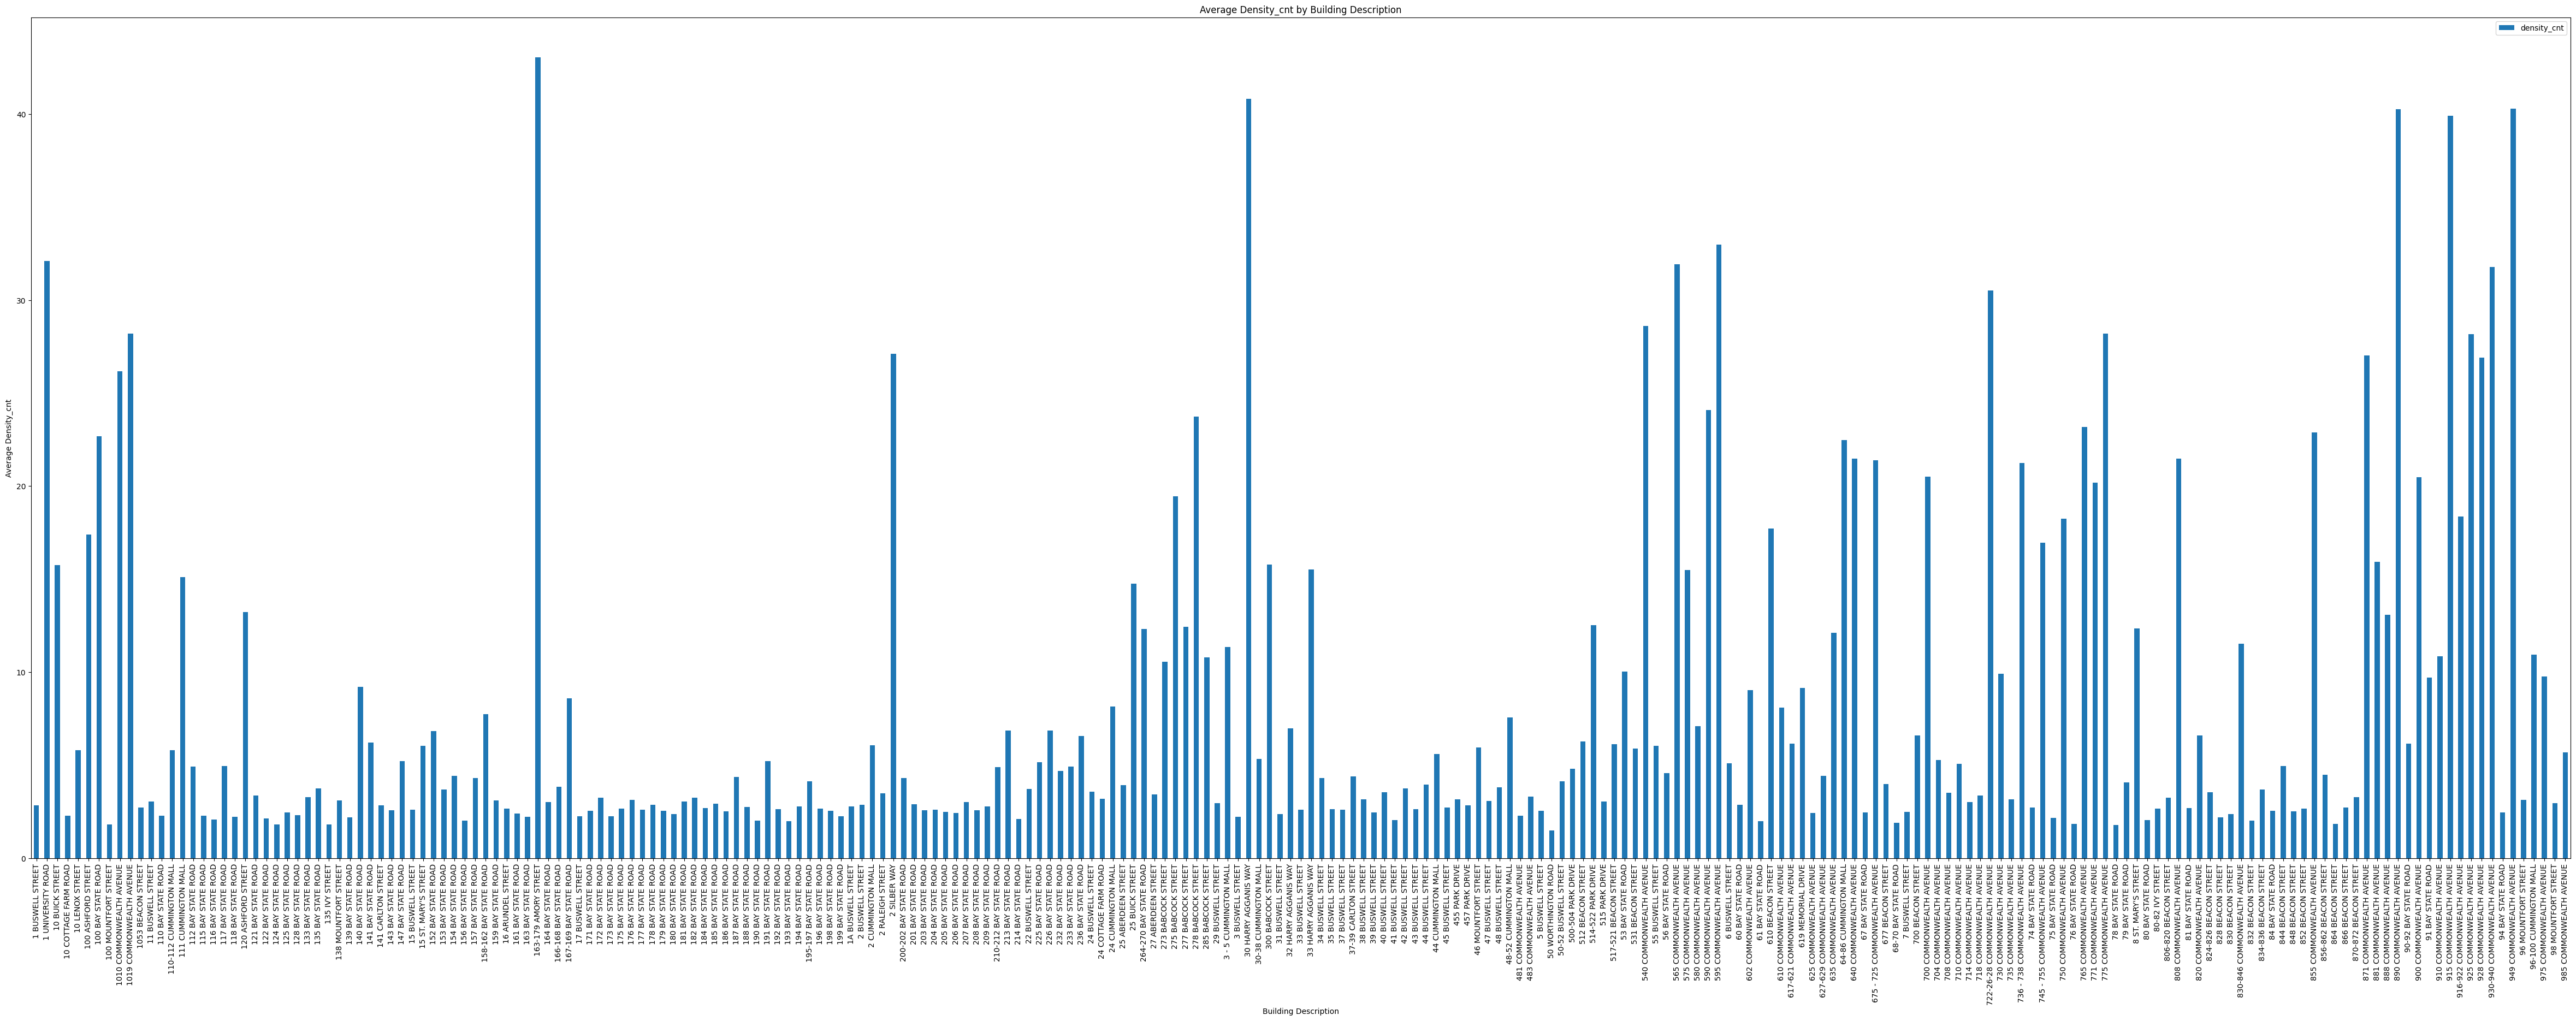

In [ ]:
grouped_df = df.groupby('building_desc')[['density_cnt']].mean()

grouped_df.plot(kind='bar', figsize=(60, 20))
plt.title('Average Density_cnt by Building Description')
plt.xlabel('Building Description')
plt.ylabel('Average Density_cnt')
plt.xticks(rotation=90)
plt.show()

From this graph, 163-179 Amory Street has the highest average density_cnt.

Even though it is difficult to graph, we can still group by the building with the hour to find the average density_cnt, capacity, and dc_ratio.

In [ ]:
grouped_df = df.groupby(['building_desc', 'hour'])[['capacity', 'dc_ratio', 'density_cnt']].mean()
grouped_df

capacity  dc_ratio  density_cnt
building_desc           hour                                  
1 BUSWELL STREET        0      3.872510  0.437251     1.792829
                        1      3.893895  0.493183     2.024709
                        2      3.869752  0.525856     2.172228
                        3      3.881617  0.555043     2.281039
                        4      3.924324  0.573829     2.353153
...                                 ...       ...          ...
985 COMMONWEALTH AVENUE 19    92.450127  0.031797     4.699241
                        20    92.025471  0.031936     4.704534
                        21    91.257451  0.032549     4.788798
                        22    92.223529  0.032900     4.813811
                        23    91.919166  0.033142     4.857143

[5826 rows x 3 columns]

We will use capacity, dc_ratio, and density_cnt to determine whether specific buildings require a water bottle filling station.

In [ ]:
from google.colab import files
df.to_csv('updated_wifi.csv', index=False)
files.download('updated_wifi.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>